In [59]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [60]:
class Value:
  
  def __init__(self, data, _children=(), _op='', label=''):
    self.data = data
    self.grad = 0.0
    self._backward = lambda: None
    self._prev = set(_children)
    self._op = _op
    self.label = label

  def __repr__(self):
    return f"Value(data={self.data})"
  
  def __add__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data + other.data, (self, other), '+')
    
    def _backward():
      self.grad += 1.0 * out.grad
      other.grad += 1.0 * out.grad
    out._backward = _backward
    
    return out

  def __mul__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data * other.data, (self, other), '*')
    
    def _backward():
      self.grad += other.data * out.grad
      other.grad += self.data * out.grad
    out._backward = _backward
      
    return out
  
  def __pow__(self, other):
    assert isinstance(other, (int, float)), "only supporting int/float powers for now"
    out = Value(self.data**other, (self,), f'**{other}')

    def _backward():
        self.grad += other * (self.data ** (other - 1)) * out.grad
    out._backward = _backward

    return out
  
  def __rmul__(self, other): # other * self
    return self * other
    
  def __truediv__(self, other): # self / other
    return self * other**-1

  def __neg__(self): # -self
    return self * -1

  def __sub__(self, other): # self - other
    return self + (-other)

  def __radd__(self, other): # other + self
    return self + other

  def tanh(self):
    x = self.data
    t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
    out = Value(t, (self, ), 'tanh')
    
    def _backward():
      self.grad += (1 - t**2) * out.grad
    out._backward = _backward
    
    return out
  
  def exp(self):
    x = self.data
    out = Value(math.exp(x), (self, ), 'exp')
    
    def _backward():
      self.grad += out.data * out.grad # NOTE: in the video I incorrectly used = instead of +=. Fixed here.
    out._backward = _backward
    
    return out
  
  def backward(self):
    
    topo = []
    visited = set()
    def build_topo(v):
      if v not in visited:
        visited.add(v)
        for child in v._prev:
          build_topo(child)
        topo.append(v)
    build_topo(self)
    
    self.grad = 1.0
    for node in reversed(topo):
      node._backward()



In [61]:

class Neuron:
  
  def __init__(self, nin):
    self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
    self.b = Value(random.uniform(-1,1))
  
  def __call__(self, x):
    # w * x + b
    act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
    out = act.tanh()
    return out
  
  def parameters(self):
    return self.w + [self.b]

class Layer:
  
  def __init__(self, nin, nout):
    self.neurons = [Neuron(nin) for _ in range(nout)]
  
  def __call__(self, x):
    outs = [n(x) for n in self.neurons]
    return outs[0] if len(outs) == 1 else outs
  
  def parameters(self):
    return [p for neuron in self.neurons for p in neuron.parameters()]

class MLP:
  
  def __init__(self, nin, nouts):
    sz = [nin] + nouts
    self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]
  
  def __call__(self, x):
    for layer in self.layers:
      x = layer(x)
    return x
  
  def parameters(self):
    return [p for layer in self.layers for p in layer.parameters()]


In [62]:
x = [2.0, 3.0, -1.0]
n = MLP(3, [4, 4, 1])
n(x)

Value(data=-0.8144370712763018)

In [63]:
xs = [
  [2.0, 3.0, -1.0],
  [3.0, -1.0, 0.5],
  [0.5, 1.0, 1.0],
  [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0] # desired targets

In [64]:

for k in range(20):
  
  # forward pass
  ypred = [n(x) for x in xs]
  loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))
  
  # backward pass
  for p in n.parameters():
    p.grad = 0.0
  loss.backward()
  
  # update
  for p in n.parameters():
    p.data += -0.1 * p.grad
  
  print(k, loss.data)
  

0 6.073692656172819
1 2.4201758354966008
2 0.7596205056806263
3 0.3439294147885473
4 0.2140056866615646
5 0.16067072933115653
6 0.1280312007243686
7 0.10605884275443908
8 0.09029952548489784
9 0.07846816306881887
10 0.06927345128079959
11 0.061931689771538435
12 0.05594027168426989
13 0.05096235895228226
14 0.04676393960464639
15 0.04317749060307988
16 0.04008000416014919
17 0.037379171131850054
18 0.03500439917069733
19 0.03290080334758737


In [65]:
ypred

[Value(data=0.9065564719427462),
 Value(data=-0.9190767596297492),
 Value(data=-0.9007082268519638),
 Value(data=0.9118995836281227)]

### 2-layer neuron rebuilt on the micrograd engine

In [66]:
def _rsub(self, other): # other - self
  return (-self) + other

def _sigmoid(self):
  s = 1.0 / (1.0 + math.exp(-self.data))
  out = Value(s, (self, ), 'sigmoid')

  def _backward():
    self.grad += s * (1 - s) * out.grad
  out._backward = _backward

  return out

def _log(self):
  out = Value(math.log(self.data), (self, ), 'log')

  def _backward():
    self.grad += (1.0 / self.data) * out.grad
  out._backward = _backward

  return out

Value.__rsub__ = _rsub
Value.sigmoid = _sigmoid
Value.log = _log

Quick check against finite differences: the derivative of $\log\sigma(z)$ at $z = 0.3$.

In [67]:
z = Value(0.3)
out = z.sigmoid().log()
out.backward()

h = 1e-6
s = lambda t: 1.0 / (1.0 + math.exp(-t))
numeric = (math.log(s(0.3 + h)) - math.log(s(0.3 - h))) / (2*h)
print('micrograd', z.grad, ' numeric', numeric)

micrograd 0.42555748318834097  numeric 0.42555748319683673


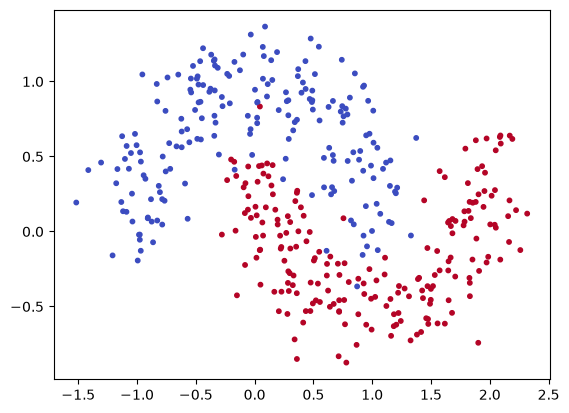

In [68]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples = 500, noise = 0.2, random_state = 40)
y = y.reshape(-1, 1)
X, X_test, y, y_test = train_test_split(X, y, test_size = 0.2, random_state = 30)

# micrograd works on plain Python floats, one example at a time
X_list = X.tolist()
y_list = y.ravel().astype(float).tolist()

plt.scatter(X[:,0], X[:,1], c=y.ravel(), cmap = "coolwarm", s=10)
plt.show()

In [69]:
class TwoLayerNet:

  def __init__(self, n_in, n_hidden, seed = 23):
    rng = random.Random(seed)
    self.W1 = [[Value(rng.gauss(0.0, 1.0/math.sqrt(n_in)), label=f'W1[{i},{j}]') for j in range(n_hidden)] for i in range(n_in)]
    self.b1 = [Value(0.0, label=f'b1[{j}]') for j in range(n_hidden)]
    self.W2 = [Value(rng.gauss(0.0, 1.0/math.sqrt(n_hidden)), label=f'W2[{j}]') for j in range(n_hidden)]
    self.b2 = Value(0.0, label='b2')

  def __call__(self, x):
    # x is a list of n_in floats; returns the predicted probability that y = 1
    H = len(self.b1)
    a1 = [sum((x[i]*self.W1[i][j] for i in range(len(x))), self.b1[j]).tanh() for j in range(H)]
    z2 = sum((a1[j]*self.W2[j] for j in range(H)), self.b2)
    return z2.sigmoid()

  def parameters(self):
    return [w for row in self.W1 for w in row] + self.b1 + self.W2 + [self.b2]

In [70]:
def bce_loss(probs, targets):
  # L = mean[-y log(a) - (1-y) log(1-a)]
  return sum(-(yi*a.log() + (1 - yi)*(1 - a).log()) for a, yi in zip(probs, targets)) * (1.0/len(targets))

def accuracy(probs, targets):
  return sum((a.data > 0.5) == (yi == 1.0) for a, yi in zip(probs, targets)) / len(targets)

In [71]:
def to_arrays(net, attr = 'data'):
  # copy the weights (or their grads) out of the Value objects into Day 2's numpy shapes
  get = lambda v: getattr(v, attr)
  return {
    "W1": np.array([[get(w) for w in row] for row in net.W1]),
    "b1": np.array([[get(b) for b in net.b1]]),
    "W2": np.array([[get(w)] for w in net.W2]),
    "b2": np.array([[get(net.b2)]]),
  }

def forward_np(X, p):
  A1 = np.tanh(X @ p["W1"] + p["b1"])
  A2 = 1.0/(1.0 + np.exp(-(A1 @ p["W2"] + p["b2"])))
  return A1, A2

def gradients_day2(X, y, p):
  m = X.shape[0]
  A1, A2 = forward_np(X, p)
  dZ2 = (A2 - y) / m
  dA1 = dZ2 @ p["W2"].T
  dZ1 = dA1 * (1 - A1**2)
  return {"W1": X.T @ dZ1, "b1": dZ1.sum(axis=0, keepdims=True),
          "W2": A1.T @ dZ2, "b2": dZ2.sum(axis=0, keepdims=True)}

net = TwoLayerNet(X.shape[1], 10)
loss = bce_loss([net(x) for x in X_list], y_list)
loss.backward()

auto = to_arrays(net, 'grad')
hand = gradients_day2(X, y, to_arrays(net, 'data'))
A2 = forward_np(X, to_arrays(net))[1]
print('loss: micrograd', loss.data, ' numpy', -np.mean(y*np.log(A2) + (1-y)*np.log(1-A2)))
for k in hand:
  diff = np.linalg.norm(auto[k] - hand[k])
  scale = np.linalg.norm(auto[k]) + np.linalg.norm(hand[k]) + 1e-12
  print(f"{k}: relative error {diff / scale:.2e}")

loss: micrograd 0.6524372165840135  numpy 0.6524372165840134
W1: relative error 1.81e-16
b1: relative error 5.08e-16
W2: relative error 2.96e-16
b2: relative error 5.97e-17


In [72]:
def train(X_list, y_list, n_hidden = 10, lr = 0.5, steps = 2000, batch_size = 32, eval_every = 250, seed = 23):
  net = TwoLayerNet(len(X_list[0]), n_hidden, seed = seed)
  rng = random.Random(seed)

  for step in range(steps + 1):
    # forward pass on a mini-batch
    idx = rng.sample(range(len(X_list)), batch_size)
    probs = [net(X_list[i]) for i in idx]
    loss = bce_loss(probs, [y_list[i] for i in idx])

    # backward pass
    for p in net.parameters():
      p.grad = 0.0
    loss.backward()

    # update
    for p in net.parameters():
      p.data -= lr * p.grad

    if step % eval_every == 0:
      all_probs = [net(x) for x in X_list]
      print(f"step {step:5d} loss {bce_loss(all_probs, y_list).data:4f} accuracy {accuracy(all_probs, y_list):3f}")
  return net

In [73]:
H = 10
net = train(X_list, y_list, n_hidden = H)

step     0 loss 0.584634 accuracy 0.857500
step   250 loss 0.260560 accuracy 0.895000
step   500 loss 0.145436 accuracy 0.950000
step   750 loss 0.096494 accuracy 0.970000
step  1000 loss 0.084246 accuracy 0.975000
step  1250 loss 0.082950 accuracy 0.970000
step  1500 loss 0.075585 accuracy 0.980000
step  1750 loss 0.078040 accuracy 0.975000
step  2000 loss 0.075098 accuracy 0.975000


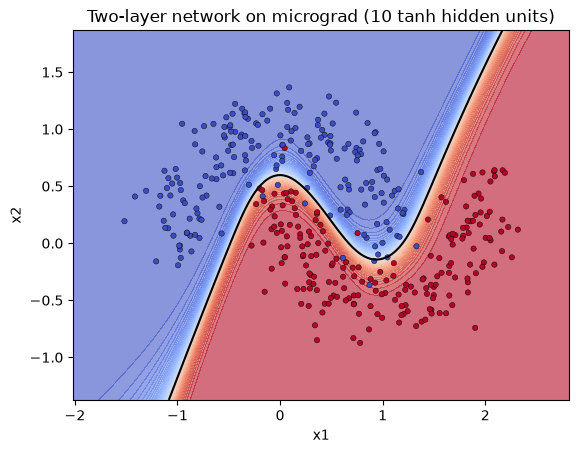

In [74]:
def plot_decision_boundary(predict, X, y, title, steps = 300, pad = 0.5):
    # predict is a function that sends X to the predicted probability that y=1

    # build a grid with some padding
    x_min, x_max = X[:,0].min() - pad, X[:,0].max() + pad
    y_min, y_max = X[:,1].min() - pad, X[:,1].max() + pad
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, steps), np.linspace(y_min, y_max, steps))

    # reshape to (N, 2) array, predict and reshape back
    grid = np.c_[xx.ravel(),yy.ravel()]
    probs = predict(grid).reshape(xx.shape)

    # draw
    plt.contourf(xx, yy, probs, levels = 50, cmap = "coolwarm", alpha = 0.6)
    plt.contour(xx, yy, probs, levels = [0.5], colors = "black", linewidths =  1.5)
    plt.scatter(X[:,0], X[:,1], c = y.ravel(), cmap = "coolwarm", edgecolors = "k", linewidths = 0.3, s = 15)
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(title)
    plt.show()

params = to_arrays(net)
plot_decision_boundary(lambda P: forward_np(P, params)[1], X, y, title = f"Two-layer network on micrograd ({H} tanh hidden units)")

In [75]:
acc = accuracy([net(x) for x in X_list], y_list)
Test_acc = accuracy([net(x) for x in X_test.tolist()], y_test.ravel().astype(float).tolist())
print(f"Training accuracy is {acc:3f} and test accuracy is {Test_acc:3f}")

Training accuracy is 0.975000 and test accuracy is 0.960000
